## 🐻‍❄️ 투빅스 25&26기 - 추천시스템 & GNN 과제 [MovieLens로 BPR-MF, NeuMF, LightGCN 직접 구현]

#### ✅ 과제 목적
세션에서 배운 추천의 흐름 - **시청 기록 → 평가 지표 → 벡터(임베딩)로 학습 → 그래프로 연결 전파** - 를 실제 데이터로 따라갑니다.
라이브러리의 완성된 모델을 불러오는 대신, 세션 슬라이드에 나온 **식을 직접 코드로 옮겨** 네 가지 추천 방법을 같은 조건에서 비교합니다.

> - **Part A. 직접 구현하고 비교하기 (필수)** - 평가 지표, 인기순, Item-CF, BPR-MF, NeuMF, LightGCN을 차례로 구현하고 Recall@20, NDCG@20으로 비교합니다.
> - **Part B. 세션의 주장을 검증하기 (심화 선택)** - "층은 깊을수록 좋은가?", "W와 σ를 빼니 더 좋아졌다", "정규화가 인기 편향을 줄이는가?"를 본인 실험으로 확인합니다.

#### 📝 기술블로그 활용 방안 (필수 확인)
이 과제의 실험, 코드, 해석은 **기술블로그 글의 재료**입니다. 아래 항목은 노트북에서 끝내지 말고 **기술블로그에 옮겨 작성**해 주세요.

| 블로그에 옮길 내용 | 노트북 위치 |
|---|---|
| ① MovieLens의 희소성 수치와 Long-tail 그래프, 그리고 "빈칸 = 모름"에 대한 본인 해석 | 1장, 서술형 문제 1 |
| ② 직접 구현한 Recall@K, NDCG@K 코드와, 세션 예시(0.40 / 0.67 / 0.70)로 검증한 과정 | 2장 |
| ③ BPR 손실, Negative Sampling, LightGCN 정규화, 전파 코드를 **식과 함께** 설명 | 4장, 6장 |
| ④ **네 모델 비교 표, 막대그래프와 해석** (가장 중요) | 7장, 서술형 문제 2, 3 |
| ⑤ (심화 선택) 층 수 실험, W/σ 실험, 인기 편향 실험의 그래프와, 세션 주장과 **같았는지 / 달랐는지**에 대한 해석 | Part B, 서술형 문제 4, 5, 6 |

> 블로그에는 **본인 시드로 나온 숫자와 그래프를 그대로** 쓰고, 결과가 세션 슬라이드와 다르게 나왔다면 그 이유를 추론해 함께 적어 주세요.

> **데이터셋:** [MovieLens-100K](https://grouplens.org/datasets/movielens/100k/) (GroupLens) - [RecBole 저장소](https://github.com/RUCAIBox/RecBole)의 사본을 내려받아 사용합니다.
> - 사용자 943명, 영화 1,682편, 별점 100,000개
> - 세션처럼 **암묵적 피드백**으로 바꿔 씁니다: 별점 4점 이상 = "봤다(좋아했다)", 나머지와 기록 없음 = 빈칸

#### ✅ 주의 사항
- **런타임 > 런타임 유형 변경 > GPU**를 켜고 시작하세요. (CPU로도 돌아가지만 Part B가 느립니다)
- `# ===== TODO n =====` 블록 안만 채우세요. 나머지 셀은 준비 코드이므로 수정하지 않습니다.
- `MY_SEED`(학번 뒷 4자리)에 따라 데이터 분할이 달라져 **사람마다 숫자가 조금씩 다릅니다.** 정상입니다.
- 각 TODO 아래의 `✅ 확인` 셀이 통과해야 다음으로 넘어갈 수 있습니다.

### 🗺️ 실습 흐름

> **Part A. 직접 구현하고 비교하기 (필수)**
0. 환경 설정
1. 데이터 만나기 - 상호작용 행렬, Sparsity, Long-tail
2. 채점 방법 만들기 - Recall@K, NDCG@K 직접 구현
3. 기준 모델 - 인기순 추천, Item-CF (Jaccard)
4. BPR-MF - 내적 점수, Negative Sampling, BPR 손실
5. NeuMF - 내적 대신 신경망
6. LightGCN - 정규화 인접행렬, 층별 전파, 층 평균
7. 네 모델 비교 + 내 시드의 사용자에게 추천된 영화 보기

> **Part B. 세션의 주장을 검증하기 (심화 선택)**
8. 층은 깊을수록 좋을까? - 층 수 실험 & Over-smoothing 측정
9. W와 σ를 다시 넣으면? - LightGCN vs NGCF 스타일
10. 정규화는 인기 편향을 줄일까? - 추천 결과의 인기도 분석

### 📖 세션 슬라이드 대응표

| 노트북 | 세션 슬라이드 |
|---|---|
| 1장 상호작용 행렬, Sparsity, Long-tail | 6~8p 데이터 이해하기, 14p 추천의 어려움 |
| 2장 Recall@K, NDCG@K | 9p 평가 방법 |
| 3장 인기순, Item-CF | 13p Item-based CF (Jaccard), 14p 인기 편향 |
| 4장 BPR-MF | 17~18p MF와 내적, 20p BPR과 Negative Sampling |
| 5장 NeuMF | 21p NCF |
| 6장 LightGCN | 25p 이분 그래프, 39~40p LightGCN 동작 방식 |
| 8장 층 수, Over-smoothing | 31p Over-smoothing, 41p 층 수 실험 |
| 9장 W와 σ | 33p GCN, 38p NGCF → LightGCN |
| 10장 인기 편향 | 14p 인기 편향, 39p 정규화 |

# 🧭 Part A. 직접 구현하고 비교하기 (필수)

### ⚙️ 0. 환경 설정 - 라이브러리, 학생별 시드, 실험 설정

In [1]:
import os, math, random, time, urllib.request

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # torch sparse 경고 숨김

# ---- 실험 설정 (모든 모델이 같은 조건) ----
EMB_DIM = 64          # 임베딩 길이
TOPK = 20             # Recall@20, NDCG@20
EPOCHS = 50          # 모델별 학습 epoch
BATCH_SIZE = 2048
LR = 5e-3
REG = 1e-4            # 임베딩 L2 정규화 계수
N_LAYERS = 3          # LightGCN 기본 층 수
POS_THRESHOLD = 4     # 별점 4점 이상 = 상호작용(봤다)

# ===== TODO 0 =====
# 힌트: 본인 학번 뒷 4자리를 넣으세요. (예: 202612345 -> 2345)
MY_SEED = 1347   # TODO: 학번 뒷 4자리
# ==================

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

assert MY_SEED is not None, "TODO 0: MY_SEED에 학번 뒷 4자리를 넣으세요."
set_seed(MY_SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device  :", device)
print("MY_SEED :", MY_SEED)
if device == "cpu":
    print("\n⚠️ GPU가 아닙니다. 런타임 > 런타임 유형 변경에서 GPU를 켜세요.")

device  : cpu
MY_SEED : 1347

⚠️ GPU가 아닙니다. 런타임 > 런타임 유형 변경에서 GPU를 켜세요.


### 📦 1. 데이터 만나기 - 상호작용 행렬, Sparsity, Long-tail

세션 7p처럼 시청 기록을 **사용자 × 영화 표**로 바꿉니다. 별점 4점 이상만 "봤다(1)"로 남기고, 나머지는 빈칸입니다.

In [2]:
# ---- MovieLens-100K 다운로드 (준비 코드) ----
# GroupLens 원본과 같은 데이터를 RecBole 공식 저장소의 사본에서 받습니다.
# (Colab에서 GroupLens 서버는 SSL 인증서 오류로 다운로드가 실패하는 경우가 있습니다)
BASE = "https://raw.githubusercontent.com/RUCAIBox/RecBole/master/dataset/ml-100k/"
for f in ["ml-100k.inter", "ml-100k.item"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)

ratings = pd.read_csv("ml-100k.inter", sep="\t")
ratings.columns = ["user", "item", "rating", "ts"]
titles = pd.read_csv("ml-100k.item", sep="\t", usecols=[0, 1])
titles.columns = ["item", "title"]

# 암묵적 피드백으로 변환: 별점 4점 이상만 상호작용으로 사용
inter = ratings[ratings.rating >= POS_THRESHOLD][["user", "item"]].drop_duplicates()

# 사용자 / 영화 번호를 0부터 다시 매기기
uid = {u: k for k, u in enumerate(sorted(inter.user.unique()))}
iid = {i: k for k, i in enumerate(sorted(inter.item.unique()))}
inter = inter.assign(u=inter.user.map(uid), i=inter.item.map(iid))
idx2title = dict(zip(titles.item.map(iid), titles.title))
n_users, n_items = len(uid), len(iid)

print("원본 별점 수        :", len(ratings))
print("상호작용 수 (4점↑) :", len(inter))
print("사용자 수 × 영화 수 : %d × %d" % (n_users, n_items))

원본 별점 수        : 100000
상호작용 수 (4점↑) : 55375
사용자 수 × 영화 수 : 942 × 1447


#### ✏️ ===== TODO 1 =====
세션 8p처럼 **빈칸 비율(Sparsity)** 을 구하세요. Sparsity = 1 − (상호작용 수 ÷ 전체 칸 수)

In [3]:
# ===== TODO 1 =====
# 힌트: 전체 칸 수 = n_users * n_items
sparsity = 1 - len(inter) / (n_users * n_items)   # TODO: 여기에 코드를 작성하세요
# ==================

# ✅ 확인
assert sparsity is not None and 0.9 < sparsity < 1.0, "Sparsity 계산을 다시 확인하세요."
print("Sparsity: %.2f%%  (세션 예시 MovieLens-1M은 약 95.5%%)" % (sparsity * 100))
print("✅ 통과")

Sparsity: 95.94%  (세션 예시 MovieLens-1M은 약 95.5%)
✅ 통과


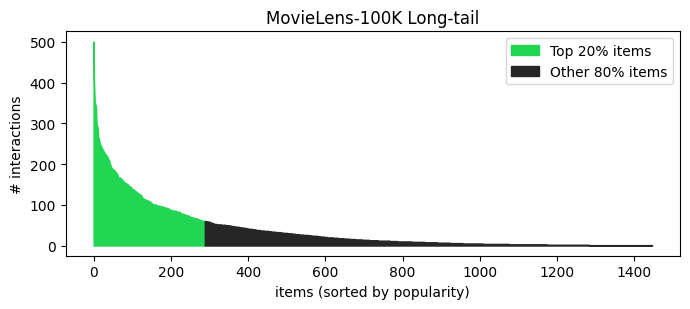

상위 20%의 영화가 전체 상호작용의 69.0%를 차지


In [4]:
# ---- Long-tail 그래프 (준비 코드) ----
item_cnt = inter.i.value_counts().sort_values(ascending=False).values
head_n = int(len(item_cnt) * 0.2)
share = item_cnt[:head_n].sum() / item_cnt.sum()

plt.figure(figsize=(7, 3.2))
plt.fill_between(range(head_n), item_cnt[:head_n], color="#22D654", label="Top 20% items")
plt.fill_between(range(head_n - 1, len(item_cnt)), item_cnt[head_n - 1:], color="#262626", label="Other 80% items")
plt.xlabel("items (sorted by popularity)"); plt.ylabel("# interactions"); plt.legend()
plt.title("MovieLens-100K Long-tail"); plt.tight_layout(); plt.show()
print("상위 20%%의 영화가 전체 상호작용의 %.1f%%를 차지" % (share * 100))

#### 📝 서술형 문제 1
1. 본인의 Sparsity 값과 Long-tail 그래프의 "상위 20% 비율"을 인용하세요.
2. 이 데이터에서 빈칸이 "싫어서 안 본 것"이 아니라 "아직 모르는 것"으로 봐야 하는 이유를, 우리가 별점 4점 미만을 **빈칸으로 처리했다**는 사실과 연결해 설명하세요. (이 처리 방식의 한계도 한 가지 적어 보세요.)

제 결과는 Sparsity 95.94%, 상위 20% 영화가 전체 상호작용의 69.0%를 차지했습니다. 942명 × 1,447편의 칸 중 채워진 것은 55,375개뿐입니다.

빈칸을 '싫어서 안 봤다'로 보면 안 되는 이유는, 우리가 별점 4점 미만을 아예 빈칸으로 처리했기 때문입니다. 지금 빈칸에는 (가) 정말 본 적이 없는 영화와 (나) 봤지만 3점 이하를 준 영화가 섞여 있습니다. (가)가 압도적으로 많고 그중 상당수는 1,447편 중 아직 눈에 띄지 않았을 뿐이라, 빈칸 전체를 '비선호'로 간주하고 벌점을 주면 아직 모르는 영화까지 싫어한다고 학습하게 됩니다. 게다가 상위 20%가 상호작용의 69.0%를 가져가는 구조라, 덜 알려진 영화의 빈칸은 대부분 노출이 없었다는 뜻에 가깝습니다. 그래서 BPR에서도 neg를 '싫어한 영화'가 아니라 '아직 pos보다 덜 선호한다고 가정하는 비교 대상'으로만 씁니다.

한계도 있습니다. 4점 미만을 버리면 실제로 보고 낮은 점수를 준 명시적 불호 정보가 통째로 사라집니다. 원래 별점 100,000개 중 55,375개만 남았는데, 버려진 쪽에는 '봤고 별로였다'는 가장 확실한 negative 신호가 들어 있습니다. 모델이 그런 영화를 추천해도 평가에서 벌점을 받지 않으므로 실제 만족도보다 점수가 좋게 나올 수 있습니다.

### 🎯 2. 채점 방법 만들기 - Recall@K, NDCG@K

세션 9p처럼 **기록 일부를 숨겨두고**(test), 모델이 추천한 상위 K개 안에 다시 나오는지 확인합니다.
분할은 사용자마다 기록의 20%를 test로 숨기며, `MY_SEED`에 따라 달라집니다.

In [5]:
# ---- train / test 분할 (준비 코드): 사용자마다 20%를 test로 ----
rng = np.random.default_rng(MY_SEED)
train_rows, test_rows = [], []
for u, g in inter.groupby("u"):
    items = g.i.values.copy(); rng.shuffle(items)
    n_test = max(1, int(round(len(items) * 0.2))) if len(items) >= 5 else 0
    test_rows += [(u, i) for i in items[:n_test]]
    train_rows += [(u, i) for i in items[n_test:]]
train_df = pd.DataFrame(train_rows, columns=["u", "i"])
test_df = pd.DataFrame(test_rows, columns=["u", "i"])

train_items = train_df.groupby("u").i.apply(set).to_dict()            # 사용자별 학습 기록
test_items = test_df.groupby("u").i.apply(set).to_dict()              # 사용자별 정답(숨긴 기록)
train_u = torch.tensor(train_df.u.values); train_i = torch.tensor(train_df.i.values)
train_mask = torch.zeros(n_users, n_items, dtype=torch.bool)   # 학습 때 본 영화면 True
train_mask[train_u, train_i] = True
print("train 상호작용: %d / test 상호작용: %d / 평가 대상 사용자: %d" % (len(train_df), len(test_df), len(test_items)))

train 상호작용: 44300 / test 상호작용: 11075 / 평가 대상 사용자: 938


#### ✏️ ===== TODO 2 =====
한 사용자의 추천 목록 `ranked`(점수 높은 순, 길이 K)와 정답 집합 `truth`로 **Recall@K**와 **NDCG@K**를 구하는 함수를 완성하세요.

- Recall@K = 상위 K개 안에서 찾은 정답 수 ÷ 정답 수
- NDCG@K = DCG ÷ IDCG,  DCG = Σ (정답이면 1) / log₂(순위 + 1),  IDCG = 정답을 모두 맨 위에 놓았을 때의 DCG

In [6]:
def recall_at_k(ranked, truth):
    # ===== TODO 2-1 =====
    # 힌트: set으로 바꿔 교집합의 크기를 세세요.
    return len(set(ranked) & set(truth)) / len(truth)   # TODO: 여기에 코드를 작성하세요
    # ==================


def ndcg_at_k(ranked, truth):
    # ===== TODO 2-2 =====
    # 힌트: 순위는 1부터 시작합니다. 1등의 할인은 1/log2(2) = 1 입니다.
    # 힌트: IDCG는 정답 개수와 K 중 작은 수만큼 1/log2(r+1)을 더한 값입니다.
    dcg = sum(1 / math.log2(r + 1) for r, it in enumerate(ranked, start=1) if it in truth)    # TODO: 여기에 코드를 작성하세요
    idcg = sum(1 / math.log2(r + 1) for r in range(1, min(len(truth), len(ranked)) + 1))   # TODO: 여기에 코드를 작성하세요
    return dcg / idcg if idcg > 0 else 0.0   # TODO: 여기에 코드를 작성하세요
    # ==================


# ✅ 확인 - 세션 9p 예시 그대로: 정답 3개, 추천 5개 중 1등과 3등이 정답
ranked = ["매트릭스", "라라랜드", "테넷", "어바웃 타임", "아바타"]
truth = {"매트릭스", "테넷", "덩케르크"}
r, n = recall_at_k(ranked, truth), ndcg_at_k(ranked, truth)
assert r is not None and n is not None, "TODO 2를 완성하세요."
print("Recall@5 = %.2f (세션: 0.67) / NDCG@5 = %.3f (세션: 0.70)" % (r, n))
assert abs(r - 2 / 3) < 1e-6 and abs(n - 0.7039) < 1e-3, "세션 예시와 값이 다릅니다."
print("✅ 통과")

Recall@5 = 0.67 (세션: 0.67) / NDCG@5 = 0.704 (세션: 0.70)
✅ 통과


In [7]:
# ---- 전체 평가 함수 (준비 코드): 학습 때 본 영화는 후보에서 제외하고 Top-K 추출 ----
@torch.no_grad()
def evaluate(score_fn, k=TOPK, return_lists=False):
    # score_fn(user_idx_tensor) -> (len(users), n_items) 점수 행렬
    users = sorted(test_items.keys())
    recalls, ndcgs, rec_lists = [], [], {}
    for s in range(0, len(users), 256):
        batch = users[s:s + 256]
        scores = score_fn(torch.tensor(batch, device=device)).float().cpu()
        for row, u in enumerate(batch):
            seen = list(train_items.get(u, ()))
            scores[row, seen] = -float("inf")
        top = torch.topk(scores, k, dim=1).indices.numpy()
        for row, u in enumerate(batch):
            ranked = top[row].tolist()
            recalls.append(recall_at_k(ranked, test_items[u]))
            ndcgs.append(ndcg_at_k(ranked, test_items[u]))
            rec_lists[u] = ranked
    out = {"Recall@%d" % k: float(np.mean(recalls)), "NDCG@%d" % k: float(np.mean(ndcgs))}
    return (out, rec_lists) if return_lists else out

results = {}   # 모델별 결과를 모아 7장에서 비교합니다

### 📏 3. 기준 모델 - 인기순 추천, Item-CF

복잡한 모델을 만들기 전에 **기준선**부터 잽니다. 이 기준선을 못 넘으면 모델을 쓸 이유가 없습니다.

#### ✏️ ===== TODO 3 =====
**인기순 추천**: 모든 사용자에게 학습 데이터에서 가장 많이 본 영화부터 추천합니다. 영화별 상호작용 수 `pop`을 구하세요.

In [8]:
# ===== TODO 3 =====
# 힌트: train_i 에서 영화 번호별 등장 횟수를 세세요. (torch.bincount, minlength=n_items)
pop = torch.bincount(train_i, minlength=n_items).float()   # TODO: 여기에 코드를 작성하세요
# ==================

assert pop is not None, "TODO 3을 완성하세요."
results["Popularity"] = evaluate(lambda users: pop.to(device).unsqueeze(0).repeat(len(users), 1))
print(results["Popularity"])

{'Recall@20': 0.17417572092122116, 'NDCG@20': 0.16059356486796408}


#### ✏️ ===== TODO 4 =====
세션 13p의 **Item-CF (Jaccard)** 입니다. 두 영화를 모두 본 사람 수 ÷ 둘 중 하나라도 본 사람 수.

`R`은 사용자 × 영화 0/1 행렬입니다. `co = Rᵀ R`의 (a, b) 칸은 a와 b를 **모두 본 사람 수**입니다.
사용자 점수는 "내가 본 영화들과의 Jaccard 유사도 합"으로 계산합니다.

In [9]:
R = torch.zeros(n_users, n_items)
R[train_u, train_i] = 1.0
co = R.T @ R                      # (n_items, n_items) 모두 본 사람 수
deg = R.sum(0)                    # 영화별 본 사람 수

# ===== TODO 4 =====
# 힌트: 둘 중 하나라도 본 사람 수 = deg[a] + deg[b] - co[a, b]  (브로드캐스팅 활용)
# 힌트: 0으로 나누지 않도록 분모에 clamp(min=1)을 쓰고, 자기 자신과의 유사도(대각선)는 0으로 두세요.
union = deg.unsqueeze(1) + deg.unsqueeze(0) - co     # TODO: 여기에 코드를 작성하세요
jaccard = co / union.clamp(min=1)
jaccard.fill_diagonal_(0.0)   # TODO: 여기에 코드를 작성하세요
# ==================

assert jaccard is not None, "TODO 4를 완성하세요."
R_dev, J_dev = R.to(device), jaccard.to(device)
results["Item-CF"] = evaluate(lambda users: R_dev[users] @ J_dev)
print(results["Item-CF"])

{'Recall@20': 0.29058154362882066, 'NDCG@20': 0.27039929089959946}


### 🧠 4. BPR-MF - 내적 점수, Negative Sampling, BPR 손실

세션 18p, 20p를 그대로 코드로 옮깁니다.
- 점수: **ŷ = 사용자 벡터와 영화 벡터의 내적**
- 학습: 시청 기록에는 '싫어요'가 없으므로, **본 영화(pos)를 안 본 영화(neg)보다 선호한다고 가정**하고 순서를 학습합니다.
- `L = − mean( ln σ(ŷ_pos − ŷ_neg) )` (+ 임베딩 L2 정규화)

#### ✏️ ===== TODO 5, 6, 7 =====

In [10]:
def sample_batch(batch_size):
    # 학습 상호작용에서 (user, pos)를 뽑고, 각 user가 보지 않은 영화를 neg로 하나씩 뽑습니다.
    idx = torch.randint(0, len(train_u), (batch_size,))
    users, pos = train_u[idx], train_i[idx]
    # ===== TODO 5 =====
    # 힌트: Negative Sampling: 무작위 영화를 뽑되, 그 사용자가 학습 때 본 영화(train_mask[users, neg]가 True)면 그 자리만 다시 뽑으세요.
    # 힌트: neg는 '싫어한 영화'가 아니라 학습용 비교 대상입니다.
    neg = torch.randint(0, n_items, (batch_size,))
    bad = train_mask[users, neg]
    while bad.any():
        neg[bad] = torch.randint(0, n_items, (int(bad.sum()),))
        bad = train_mask[users, neg]   # TODO: 여기에 코드를 작성하세요
    # ==================
    return users.to(device), pos.to(device), neg.to(device)


def bpr_loss(pos_score, neg_score):
    # ===== TODO 6 =====
    # 힌트: F.logsigmoid 를 쓰면 수치적으로 안정적입니다.
    return -F.logsigmoid(pos_score - neg_score).mean()   # TODO: 여기에 코드를 작성하세요
    # ==================


class MF(nn.Module):
    def __init__(self):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, EMB_DIM)
        self.item_emb = nn.Embedding(n_items, EMB_DIM)
        nn.init.normal_(self.user_emb.weight, std=0.1)
        nn.init.normal_(self.item_emb.weight, std=0.1)

    def score(self, users, items):
        # users, items 는 같은 길이의 번호 텐서. 각 쌍의 점수를 돌려줍니다.
        # ===== TODO 7 =====
        # 힌트: 세션 18p: 두 벡터의 내적 = 같은 위치끼리 곱해서 더하기
        return (self.user_emb(users) * self.item_emb(items)).sum(-1)   # TODO: 여기에 코드를 작성하세요
        # ==================

    def full_scores(self, users):
        return self.user_emb(users) @ self.item_emb.weight.T

    def reg(self, users, pos, neg):
        return (self.user_emb(users).pow(2).sum() + self.item_emb(pos).pow(2).sum() + self.item_emb(neg).pow(2).sum()) / len(users)

In [11]:
# ---- 공통 학습 루프 (준비 코드): 모든 모델을 같은 BPR, 같은 epoch로 학습 ----
def train_model(model, epochs=EPOCHS, verbose=True):
    set_seed(MY_SEED)
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    steps = max(1, len(train_u) // BATCH_SIZE)
    curve = []
    for ep in range(1, epochs + 1):
        model.train(); total = 0.0
        for _ in range(steps):
            u, p, n = sample_batch(BATCH_SIZE)
            loss = bpr_loss(model.score(u, p), model.score(u, n)) + REG * model.reg(u, p, n)
            opt.zero_grad(); loss.backward(); opt.step(); total += loss.item()
        if ep % 10 == 0 or ep == epochs:
            model.eval(); m = evaluate(model.full_scores); curve.append((ep, m["Recall@%d" % TOPK]))
            if verbose:
                print("epoch %3d | loss %.4f | Recall@%d %.4f | NDCG@%d %.4f" % (ep, total / steps, TOPK, m["Recall@%d" % TOPK], TOPK, m["NDCG@%d" % TOPK]))
    model.eval()
    return model, curve

# ✅ 확인
u, p, n = sample_batch(512)
assert all(n[k].item() not in train_items[u[k].item()] for k in range(512)), "neg 중에 사용자가 본 영화가 섞여 있습니다."
assert abs(bpr_loss(torch.tensor([2.0]), torch.tensor([0.0])).item() - 0.1269) < 1e-3, "BPR 손실 식을 확인하세요."
print("✅ 통과")

t0 = time.time()
mf, _ = train_model(MF())
results["BPR-MF"] = evaluate(mf.full_scores)
print("BPR-MF:", results["BPR-MF"], "(%.0f초)" % (time.time() - t0))

✅ 통과


epoch  10 | loss 0.1970 | Recall@20 0.2788 | NDCG@20 0.2419


epoch  20 | loss 0.1058 | Recall@20 0.3156 | NDCG@20 0.2667


epoch  30 | loss 0.0731 | Recall@20 0.3068 | NDCG@20 0.2587


epoch  40 | loss 0.0559 | Recall@20 0.3049 | NDCG@20 0.2540


epoch  50 | loss 0.0470 | Recall@20 0.2996 | NDCG@20 0.2506
BPR-MF: {'Recall@20': 0.29960352838124216, 'NDCG@20': 0.25060644768120766} (18초)


### 🧪 5. NeuMF - 내적 대신 신경망

세션 21p의 NCF입니다. **GMF**(두 벡터의 원소별 곱)와 **MLP**(두 벡터를 이어 붙여 신경망 통과) 두 갈래를 합쳐 점수를 냅니다.

> 원 논문(He et al., 2017)은 이진 교차엔트로피로 학습했지만, 이 과제는 **공정한 비교를 위해 모든 모델을 같은 BPR 손실**로 학습합니다.

#### ✏️ ===== TODO 8 =====

In [12]:
class NeuMF(nn.Module):
    def __init__(self, hidden=(64, 32)):
        super().__init__()
        self.gmf_u, self.gmf_i = nn.Embedding(n_users, EMB_DIM), nn.Embedding(n_items, EMB_DIM)
        self.mlp_u, self.mlp_i = nn.Embedding(n_users, EMB_DIM), nn.Embedding(n_items, EMB_DIM)
        for e in (self.gmf_u, self.gmf_i, self.mlp_u, self.mlp_i):
            nn.init.normal_(e.weight, std=0.1)
        layers, prev = [], 2 * EMB_DIM
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]; prev = h
        self.mlp = nn.Sequential(*layers)
        self.out = nn.Linear(EMB_DIM + prev, 1)   # [GMF 출력, MLP 출력] -> 점수

    def score(self, users, items):
        # ===== TODO 8 =====
        # 힌트: gmf = 두 GMF 벡터의 원소별 곱 (합하지 않습니다)
        # 힌트: mlp = 두 MLP 벡터를 이어 붙여(torch.cat) self.mlp 통과
        # 힌트: 두 결과를 이어 붙여 self.out 에 넣고 마지막 차원을 없애세요 (.squeeze(-1))
        gmf = self.gmf_u(users) * self.gmf_i(items)   # TODO: 여기에 코드를 작성하세요
        mlp = self.mlp(torch.cat([self.mlp_u(users), self.mlp_i(items)], dim=-1))   # TODO: 여기에 코드를 작성하세요
        return self.out(torch.cat([gmf, mlp], dim=-1)).squeeze(-1)  # TODO: 여기에 코드를 작성하세요
        # ==================

    def full_scores(self, users):
        # 사용자마다 모든 영화의 점수를 계산 (준비 코드)
        out = []
        all_items = torch.arange(n_items, device=users.device)
        for u in users:
            out.append(self.score(u.repeat(n_items), all_items))
        return torch.stack(out)

    def reg(self, users, pos, neg):
        e = [self.gmf_u(users), self.mlp_u(users), self.gmf_i(pos), self.mlp_i(pos), self.gmf_i(neg), self.mlp_i(neg)]
        return sum(x.pow(2).sum() for x in e) / len(users)


# ✅ 확인
_m = NeuMF().to(device)
assert _m.score(torch.tensor([0, 1], device=device), torch.tensor([2, 3], device=device)).shape == (2,), "score 출력 모양은 (batch,) 이어야 합니다."
print("✅ 통과")

t0 = time.time()
neumf, _ = train_model(NeuMF())
results["NeuMF"] = evaluate(neumf.full_scores)
print("NeuMF:", results["NeuMF"], "(%.0f초)" % (time.time() - t0))

✅ 통과


epoch  10 | loss 0.1261 | Recall@20 0.2706 | NDCG@20 0.2333


epoch  20 | loss 0.0604 | Recall@20 0.2795 | NDCG@20 0.2398


epoch  30 | loss 0.0435 | Recall@20 0.2670 | NDCG@20 0.2179


epoch  40 | loss 0.0355 | Recall@20 0.2532 | NDCG@20 0.2072


epoch  50 | loss 0.0307 | Recall@20 0.2503 | NDCG@20 0.2078


NeuMF: {'Recall@20': 0.25033177491027303, 'NDCG@20': 0.2077731166738143} (47초)


### 🕸️ 6. LightGCN - 정규화 인접행렬, 층별 전파, 층 평균

세션 25p, 39p, 40p를 코드로 옮깁니다.
1. 사용자 + 영화를 노드로 하는 **이분 그래프의 인접행렬 A** ((n_users + n_items) × (n_users + n_items))
2. **대칭 정규화** Â = D^(-1/2) A D^(-1/2) → 연결 (u, i)의 가중치는 1 / √(|N_u| × |N_i|)
3. **전파** E⁽ᵏ⁺¹⁾ = Â E⁽ᵏ⁾ (W와 σ 없음)
4. **층 평균** E = (E⁽⁰⁾ + … + E⁽ᴷ⁾) / (K + 1), 점수 = 사용자 벡터와 영화 벡터의 내적

#### ✏️ ===== TODO 9 =====
`edges`(사용자 번호, 영화 번호) 목록으로 정규화 인접행렬을 만드는 함수를 완성하세요. 영화 노드 번호는 `n_users + 영화 번호`입니다.

In [13]:
def build_norm_adj(edge_u, edge_i, n_u, n_i):
    N = n_u + n_i
    rows = torch.cat([edge_u, edge_i + n_u])          # 사용자 -> 영화
    cols = torch.cat([edge_i + n_u, edge_u])          # 영화 -> 사용자 (양방향)
    deg = torch.bincount(rows, minlength=N).float()   # 노드별 연결 수
    # ===== TODO 9 =====
    # 힌트: 각 연결 (r, c)의 값 = 1 / sqrt(deg[r] * deg[c])
    vals = 1.0 / torch.sqrt(deg[rows] * deg[cols])   # TODO: 여기에 코드를 작성하세요
    # ==================
    return torch.sparse_coo_tensor(torch.stack([rows, cols]), vals, (N, N)).coalesce()


# ✅ 확인 - 세션 예시 그대로 (가빈, 철수, 영희 × 인터스텔라, 인셉션, 매트릭스, 라라랜드, 어바웃 타임)
toy_u = torch.tensor([0, 0, 1, 1, 1, 2, 2, 2])
toy_i = torch.tensor([0, 1, 0, 1, 2, 1, 3, 4])
toy = build_norm_adj(toy_u, toy_i, 3, 5).to_dense()
w1, w2 = toy[0, 3 + 0].item(), toy[0, 3 + 1].item()
print("가빈-인터스텔라: %.2f (세션: 0.50) / 가빈-인셉션: %.2f (세션: 0.41)" % (w1, w2))
assert abs(w1 - 0.5) < 1e-4 and abs(w2 - 1 / math.sqrt(6)) < 1e-4, "정규화 식을 확인하세요."
print("✅ 통과")

가빈-인터스텔라: 0.50 (세션: 0.50) / 가빈-인셉션: 0.41 (세션: 0.41)
✅ 통과


#### ✏️ ===== TODO 10 =====
`propagate`를 완성하세요. 0층(초기 임베딩)부터 K층까지의 벡터를 리스트에 모은 뒤 **평균**을 냅니다.
학습되는 파라미터는 0층의 초기 임베딩뿐이라는 점(세션 40p)을 코드에서 확인해 보세요.

In [14]:
class LightGCN(nn.Module):
    def __init__(self, n_layers=N_LAYERS):
        super().__init__()
        self.n_layers = n_layers
        self.emb = nn.Embedding(n_users + n_items, EMB_DIM)   # 0층 = MF와 같은 초기 임베딩
        nn.init.normal_(self.emb.weight, std=0.1)
        self.A = build_norm_adj(train_u, train_i, n_users, n_items).to(device)

    def layer_embs(self):
        # 0층 ~ K층 벡터 리스트를 돌려줍니다.
        # ===== TODO 10 =====
        # 힌트: layers = [0층 벡터] 로 시작해서, 매 층마다 torch.sparse.mm(self.A, 직전 층 벡터)를 붙이세요.
        layers = [self.emb.weight]
        for _ in range(self.n_layers):
            layers.append(torch.sparse.mm(self.A, layers[-1]))   # TODO: 여기에 코드를 작성하세요
        return layers
        # ==================

    def propagate(self):
        final = torch.stack(self.layer_embs(), dim=0).mean(dim=0)   # 층 평균
        return final[:n_users], final[n_users:]

    def score(self, users, items):
        U, I = self.propagate()
        return (U[users] * I[items]).sum(-1)

    def full_scores(self, users):
        U, I = self.propagate()
        return U[users] @ I.T

    def reg(self, users, pos, neg):   # 정규화는 0층 임베딩에만 (논문과 동일)
        e0 = self.emb.weight
        return (e0[users].pow(2).sum() + e0[n_users + pos].pow(2).sum() + e0[n_users + neg].pow(2).sum()) / len(users)


# ✅ 확인
_g = LightGCN().to(device)
assert len(_g.layer_embs()) == N_LAYERS + 1, "0층부터 K층까지 K+1개의 벡터가 있어야 합니다."
print("학습 파라미터 수 - MF: %d / LightGCN: %d" % (sum(p.numel() for p in MF().parameters()), sum(p.numel() for p in _g.parameters())))
print("✅ 통과")

t0 = time.time()
lgcn, _ = train_model(LightGCN())
results["LightGCN"] = evaluate(lgcn.full_scores)
print("LightGCN:", results["LightGCN"], "(%.0f초)" % (time.time() - t0))

학습 파라미터 수 - MF: 152896 / LightGCN: 152896
✅ 통과


epoch  10 | loss 0.2769 | Recall@20 0.2634 | NDCG@20 0.2270


epoch  20 | loss 0.2172 | Recall@20 0.3010 | NDCG@20 0.2650


epoch  30 | loss 0.1920 | Recall@20 0.3249 | NDCG@20 0.2864


epoch  40 | loss 0.1669 | Recall@20 0.3345 | NDCG@20 0.2968


epoch  50 | loss 0.1478 | Recall@20 0.3420 | NDCG@20 0.3060


LightGCN: {'Recall@20': 0.34198029171762256, 'NDCG@20': 0.30597483129747033} (365초)


### 📊 7. 네 모델 비교 (+ 기준 모델)

,Recall@20,NDCG@20
Popularity,0.1742,0.1606
Item-CF,0.2906,0.2704
BPR-MF,0.2996,0.2506
NeuMF,0.2503,0.2078
LightGCN,0.3420,0.3060


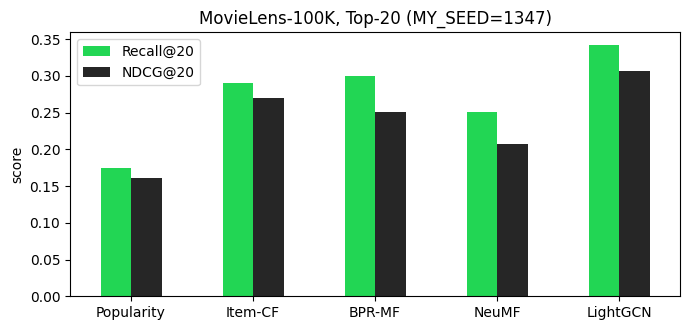

In [15]:
res_df = pd.DataFrame(results).T
display(res_df.style.format("{:.4f}").highlight_max(color="#D3F7DD"))

ax = res_df.plot.bar(figsize=(7, 3.4), color=["#22D654", "#262626"], rot=0)
ax.set_title("MovieLens-100K, Top-%d (MY_SEED=%s)" % (TOPK, MY_SEED)); ax.set_ylabel("score")
plt.tight_layout(); plt.show()

#### 👀 7-1. 내 시드의 사용자에게 무엇이 추천됐는지 보기

In [16]:
show_u = sorted(test_items.keys())[MY_SEED % len(test_items)]
print("사용자 %d 가 학습 때 본 영화 (일부):" % show_u, [idx2title[i] for i in list(train_items[show_u])[:6]])
print("숨겨둔 정답 (test):", [idx2title[i] for i in test_items[show_u]][:6])
for name, mdl in [("BPR-MF", mf), ("LightGCN", lgcn)]:
    sc = mdl.full_scores(torch.tensor([show_u], device=device))[0].detach().cpu()
    sc[list(train_items[show_u])] = -float("inf")
    top = torch.topk(sc, 5).indices.tolist()
    print("\n[%s] Top-5:" % name)
    for r, i in enumerate(top, 1):
        print("  %d. %s %s" % (r, idx2title[i], "✓ 정답" if i in test_items[show_u] else ""))

사용자 411 가 학습 때 본 영화 (일부): ['Toy Story', '2001: A Space Odyssey', 'Murder in the First', 'Leaving Las Vegas', 'Swingers', 'Taxi Driver']
숨겨둔 정답 (test): ['Ben-Hur', 'Twelve Monkeys', 'Empire Strikes Back, The', 'Raiders of the Lost Ark', 'GoodFellas', 'Close Shave, A']

[BPR-MF] Top-5:
  1. Jurassic Park 
  2. Blade Runner 
  3. Star Wars 
  4. Graduate, The 
  5. Godfather, The 

[LightGCN] Top-5:
  1. Star Wars 
  2. Fargo 
  3. Silence of the Lambs, The 
  4. Raiders of the Lost Ark ✓ 정답
  5. Godfather, The 


#### 📝 서술형 문제 2
1. 7장의 표에서 다섯 결과(Popularity(인기순), Item-CF, BPR-MF, NeuMF, LightGCN)를 Recall@20 기준으로 순서대로 나열하고 숫자를 인용하세요.
2. **인기순 추천이 생각보다 강하게 나왔다면(또는 약하게 나왔다면)** 그 이유를 1장의 Long-tail 결과와 연결해 설명하세요.
3. 세션 21p는 "잘 튜닝한 MF가 NCF를 이기기도 한다(Rendle et al., 2020)"고 했습니다. 본인 결과에서 BPR-MF와 NeuMF 중 무엇이 더 좋았나요? 같은 epoch, 같은 학습률로 비교한 이 실험이 **공정한 비교인지** 한 가지 이상의 근거로 판단하세요.

**1.** Recall@20 기준으로 LightGCN 0.3420 > BPR-MF 0.2996 > Item-CF 0.2906 > NeuMF 0.2503 > Popularity 0.1742였습니다. NDCG@20으로 보면 LightGCN 0.3060 > Item-CF 0.2704 > BPR-MF 0.2506 > NeuMF 0.2078 > Popularity 0.1606으로 BPR-MF와 Item-CF의 순서가 바뀝니다. BPR-MF는 맞히기는 비슷하게 맞혔지만 정답을 상위에 올리는 능력은 Item-CF보다 낮았다는 뜻입니다.

**2.** 인기순 추천은 개인화를 전혀 하지 않는데도 Recall@20 0.1742가 나왔습니다. 1,447편 중 똑같은 20편을 938명 모두에게 추천해서 숨겨둔 정답의 17.4%를 맞힌 셈이니, 기준선치고는 강하다고 봤습니다. 1장의 long-tail 결과가 그대로 이유가 됩니다. 상위 20% 영화가 전체 상호작용의 69.0%를 차지하므로 test에 숨겨진 상호작용도 대부분 인기작입니다. 즉 아무에게나 인기작을 주면 꽤 맞습니다. 그래도 LightGCN(0.3420)의 절반 수준이라, 개인화가 더해질 때 얻는 이득이 분명히 있다는 것도 같이 보였습니다.

**3.** 제 결과에서는 BPR-MF(0.2996 / 0.2506)가 NeuMF(0.2503 / 0.2078)보다 좋았습니다. 세션 21p의 Rendle et al.(2020) 이야기와 같은 방향입니다. 다만 이 비교가 공정하냐고 물으면 아니라고 답하겠습니다. 근거는 두 가지입니다. 첫째, 두 모델 다 학습 곡선이 20 epoch에서 꺾였습니다. BPR-MF는 epoch 20에서 Recall 0.3156이 최고였고 50 epoch에서 0.2996으로 내려왔고, NeuMF도 epoch 20에서 0.2795였다가 50 epoch에서 0.2503이 됐습니다. 즉 두 모델 모두 과적합 구간의 값을 최종 성적으로 쓴 셈이고, 조기 종료만 넣어도 순위는 그대로여도 격차는 달라집니다(0.3156 대 0.2795). 둘째, NeuMF는 GMF 임베딩, MLP 임베딩, MLP 층까지 있어 파라미터가 더 많고 구조도 다른데 학습률 5e-3과 epoch 50을 두 모델에 똑같이 썼습니다. 모델별로 하이퍼파라미터를 따로 탐색하지 않은 비교라서, 'MF가 NCF보다 낫다'가 아니라 '이 설정에서는 MF가 더 좋았다'까지만 말할 수 있다고 생각합니다.

#### 📝 서술형 문제 3
LightGCN과 BPR-MF는 학습 파라미터 수가 같습니다(6장 확인 셀 출력 인용). 그런데도 성능이 다르게 나왔다면, 그 차이는 **어디에서** 온 것인가요? 6장의 전파 식과 세션 30p("3층이면 매트릭스(3-hop)의 정보까지 반영")를 연결해 설명하세요.

6장 확인 셀에서 학습 파라미터 수는 MF 152,896, LightGCN 152,896으로 정확히 같았습니다. 그런데 Recall@20은 0.2996 대 0.3420, NDCG@20은 0.2506 대 0.3060으로 LightGCN이 앞섰습니다.

차이는 파라미터가 아니라 **임베딩을 쓰기 전에 그래프로 한 번 섞는 과정**에서 왔다고 봅니다. LightGCN은 매 층에서 E^(k+1) = D^(-1/2) A D^(-1/2) E^(k) 를 계산하고 층들의 평균을 최종 임베딩으로 씁니다. MF는 사용자 벡터가 자기 기록으로만 갱신되지만, LightGCN의 1층은 내가 본 영화들의 벡터 평균이 섞이고, 2층은 그 영화를 본 다른 사용자가, 3층은 그 사용자들이 본 또 다른 영화가 섞입니다. 세션 30p의 '3층이면 3-hop 정보까지 반영'이 이 뜻이고, 직접 연결이 없어도 두세 다리 건너 비슷한 취향이 전달됩니다.

이걸 뒷받침하는 숫자가 8장에 있습니다. 전파를 아예 끈 0층 LightGCN은 Recall@20 0.3037 / NDCG@20 0.2515로 BPR-MF(0.2996 / 0.2506)와 사실상 같은 성능이었습니다. 구조가 같은 상태에서 전파만 켰을 때 0.3433(1층), 0.3539(2층)로 올라갔으니, 차이의 출처가 파라미터 수가 아니라 전파라는 것이 분명합니다. 7-1에서 사용자 411에게 BPR-MF는 정답을 하나도 못 맞혔지만 LightGCN은 4위에 Raiders of the Lost Ark를 올린 것도 같은 맥락으로 읽었습니다.

# 🔍 Part B. 세션의 주장을 검증하기 (심화 선택)

> ⚠️ 아래 실험은 **세션 슬라이드와 다른 결과가 나올 수 있습니다.** 그래도 그대로 보고하고 원인을 추론하세요.
> 시간 여유가 있다면 `MY_SEED`를 바꿔 한두 번 더 돌려 보고, 결론이 시드에 따라 흔들리는지도 확인하면 좋습니다.

### 🧱 8. 층은 깊을수록 좋을까? - 층 수 실험 & Over-smoothing 측정

세션 41p는 "Gowalla 실험에서는 3층 이후 개선이 작았다"고 했습니다. 이 데이터에서는 어떨까요?
**0층**은 전파가 없으므로 사실상 **BPR-MF와 같은 모델**입니다.

#### ✏️ ===== TODO 11 =====
Over-smoothing을 숫자로 재기 위해, 벡터들이 서로 얼마나 비슷해졌는지 **평균 cosine 유사도**를 구하는 함수를 완성하세요.

0층: {'Recall@20': 0.3036886373449174, 'NDCG@20': 0.251479259712478} (20초)


1층: {'Recall@20': 0.3433210760322964, 'NDCG@20': 0.29989166976508186} (153초)


2층: {'Recall@20': 0.35386246541794836, 'NDCG@20': 0.3165943451533313} (287초)


3층: {'Recall@20': 0.34150868903879567, 'NDCG@20': 0.30613447413823835} (412초)


4층: {'Recall@20': 0.3320176793860375, 'NDCG@20': 0.2955238453481154} (499초)


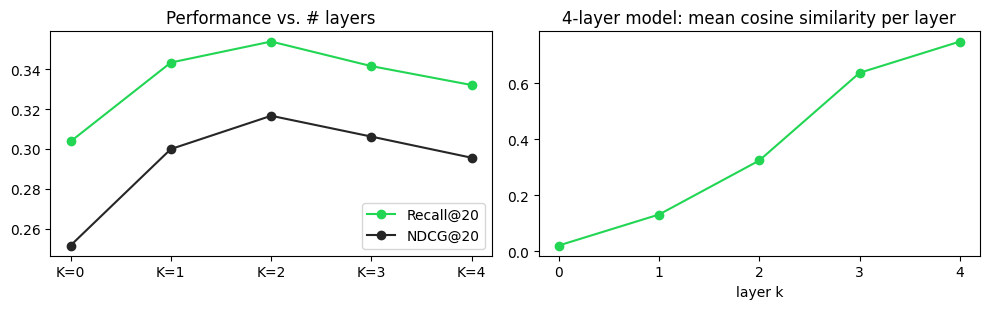

,Recall@20,NDCG@20
K=0,0.3037,0.2515
K=1,0.3433,0.2999
K=2,0.3539,0.3166
K=3,0.3415,0.3061
K=4,0.3320,0.2955


In [17]:
def mean_cosine(E, n_sample=500):
    idx = torch.randperm(E.size(0))[:n_sample]
    # ===== TODO 11 =====
    # 힌트: 행마다 L2 정규화 → 내적 행렬 → 대각선(자기 자신)을 뺀 나머지의 평균
    X = F.normalize(E[idx], dim=1)
    S = X @ X.T
    n = S.size(0)
    return float((S.sum() - S.diagonal().sum()) / (n * (n - 1)))   # TODO: 여기에 코드를 작성하세요
    # ==================


layer_res, cos_by_layer = {}, None
for K in [0, 1, 2, 3, 4]:
    t0 = time.time()
    m, _ = train_model(LightGCN(n_layers=K), verbose=False)
    layer_res["K=%d" % K] = evaluate(m.full_scores)
    print("%d층: %s (%.0f초)" % (K, layer_res["K=%d" % K], time.time() - t0))
    if K == 4:
        with torch.no_grad():
            cos_by_layer = [mean_cosine(E.detach().cpu()) for E in m.layer_embs()]

layer_df = pd.DataFrame(layer_res).T
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
layer_df.plot(ax=axs[0], marker="o", color=["#22D654", "#262626"]); axs[0].set_title("Performance vs. # layers")
axs[1].plot(range(5), cos_by_layer, marker="o", color="#22D654"); axs[1].set_xticks(range(5))
axs[1].set_title("4-layer model: mean cosine similarity per layer"); axs[1].set_xlabel("layer k")
plt.tight_layout(); plt.show()
display(layer_df.style.format("{:.4f}"))

#### 📝 서술형 문제 4
1. 본인 결과에서 성능이 가장 좋았던 층 수와, 0층(≈ MF) 대비 향상 폭을 인용하세요.
2. 오른쪽 그래프에서 층이 깊어질수록 평균 cosine 유사도가 어떻게 변했나요? 이것이 세션 31p의 Over-smoothing과 같은 현상인지 판단하세요.
3. LightGCN이 마지막 층만 쓰지 않고 **층 평균**을 쓰는 이유를, 이 두 그래프를 근거로 설명하세요.

**1.** 가장 좋았던 것은 2층으로 Recall@20 0.3539 / NDCG@20 0.3166이었습니다. 0층(≈ MF)은 0.3037 / 0.2515였으니 Recall은 0.3037에서 0.3539로, NDCG는 0.2515에서 0.3166으로 올랐습니다. 비율로는 Recall 약 17%, NDCG 약 26% 향상입니다. 3층 0.3415, 4층 0.3320으로 2층 이후에는 오히려 떨어졌습니다. 세션 41p가 말한 '3층 이후 개선이 작다'보다 더 이른 2층에서 꺾였는데, MovieLens-100K가 Gowalla보다 훨씬 작아서 몇 hop만에 그래프 대부분이 서로 닿기 때문이라고 추측했습니다.

**2.** 오른쪽 그래프에서 4층 모델의 층별 평균 cosine 유사도는 0층 약 0.02에서 시작해 1층 약 0.13, 2층 약 0.33, 3층 약 0.64, 4층 약 0.75로 단조 증가했습니다. 층을 거칠수록 모든 노드의 벡터가 서로 비슷해지고 있다는 뜻이고, 세션 31p의 Over-smoothing과 같은 현상으로 판단했습니다. 벡터가 다 비슷해지면 내적 점수의 순위가 사용자마다 구분되지 않으므로, 성능이 2층 이후 내려간 것과도 맞아떨어집니다. 다만 0.75는 '완전히 한 점으로 붕괴'까지는 아니라서, 4층에서도 0.3320으로 MF보다는 높았습니다.

**3.** 두 그래프를 겹쳐 보면 이유가 보입니다. 성능은 2층에서 가장 좋은데 cosine 유사도는 층이 깊을수록 계속 커집니다. 즉 깊은 층은 더 넓은 이웃 정보를 가져오는 대신 개별성을 잃습니다. 마지막 층만 쓰면 그 층의 평활화를 그대로 뒤집어쓰게 되는데, 층 평균을 쓰면 거의 평활화되지 않은 0층(cosine 0.02)의 개별 정보와 1~3층의 이웃 정보가 함께 남습니다. 서로 다른 hop의 정보를 섞는 동시에 과하게 뭉개지는 것을 막는 장치인 셈입니다.

### ⚖️ 9. W와 σ를 다시 넣으면? - LightGCN vs NGCF 스타일

세션 38p: "ID와 상호작용만 쓰는 협업 필터링 **실험에서는** W와 σ를 뺀 쪽이 더 나았다."
LightGCN의 매 층에 **선형 변환 W와 활성화 함수 σ(LeakyReLU)** 를 다시 넣어 직접 비교합니다.

#### ✏️ ===== TODO 12 =====

In [18]:
class LightGCNWithW(LightGCN):
    def __init__(self, n_layers=N_LAYERS):
        super().__init__(n_layers)
        self.W = nn.ModuleList([nn.Linear(EMB_DIM, EMB_DIM) for _ in range(n_layers)])

    def layer_embs(self):
        # ===== TODO 12 =====
        # 힌트: 직전 층 벡터를 전파한 뒤(torch.sparse.mm) → self.W[k] 로 변환 → F.leaky_relu(…, 0.2) 를 적용하세요.
        layers = [self.emb.weight]
        for k in range(self.n_layers):
            h = torch.sparse.mm(self.A, layers[-1])
            layers.append(F.leaky_relu(self.W[k](h), 0.2))   # TODO: 여기에 코드를 작성하세요
        return layers
        # ==================


t0 = time.time()
lgcn_w, _ = train_model(LightGCNWithW())
results_w = {"LightGCN": results["LightGCN"], "LightGCN + W + sigma": evaluate(lgcn_w.full_scores)}
display(pd.DataFrame(results_w).T.style.format("{:.4f}"))
print("(%.0f초)" % (time.time() - t0))

epoch  10 | loss 0.2682 | Recall@20 0.2380 | NDCG@20 0.2111


epoch  20 | loss 0.2157 | Recall@20 0.2913 | NDCG@20 0.2514


epoch  30 | loss 0.1984 | Recall@20 0.3064 | NDCG@20 0.2699


epoch  40 | loss 0.1763 | Recall@20 0.3195 | NDCG@20 0.2803


epoch  50 | loss 0.1579 | Recall@20 0.3331 | NDCG@20 0.2997


,Recall@20,NDCG@20
LightGCN,0.3420,0.3060
LightGCN + W + sigma,0.3331,0.2997


(462초)


#### 📝 서술형 문제 5
1. W와 σ를 넣은 모델이 더 좋았나요, 나빴나요? 숫자를 인용하세요.
2. 결과가 세션 38p와 **같았다면** 그 이유를, **달랐다면** 가능한 원인(epoch 수, 학습률, 데이터 크기 등)을 추론하세요.
3. 만약 영화에 장르, 줄거리 같은 **콘텐츠 특징**이 있었다면, W의 역할이 어떻게 달라질 수 있을지 생각해 보세요.

**1.** 더 나빴습니다. LightGCN은 Recall@20 0.3420 / NDCG@20 0.3060인데 W와 LeakyReLU를 넣은 쪽은 0.3331 / 0.2997이었습니다. 두 지표 모두 조금씩 내려갔습니다.

**2.** 방향은 세션 38p와 같았지만 차이가 아주 크지는 않았습니다(Recall 0.0089, NDCG 0.0063). 이유를 이렇게 봤습니다. 여기서 입력은 ID 임베딩뿐이라 각 노드가 가진 것은 학습으로 만들어진 좌표값밖에 없습니다. W를 곱하고 비선형을 씌워도 변환할 '특징'이 따로 없고, 오히려 층마다 64×64 가중치가 추가되어 같은 50 epoch·같은 학습률에서 학습해야 할 양만 늘어납니다. 실제로 W 버전의 학습 곡선은 epoch 50에서 Recall 0.3331로 아직 오르는 중이었고(epoch 40 0.3195 → 50 0.3331), LightGCN도 0.3345 → 0.3420으로 오르는 중이라 두 모델 모두 수렴 전입니다. epoch을 더 주거나 학습률을 따로 맞췄다면 격차가 줄거나 뒤집혔을 수도 있다고 생각합니다. 데이터가 작아(상호작용 44,300개) 파라미터가 늘수록 불리하다는 점도 영향을 줬을 것 같습니다.

**3.** 장르나 줄거리 같은 콘텐츠 특징이 입력으로 들어온다면 W의 역할이 달라진다고 봅니다. 그때는 서로 다른 의미의 차원(장르 one-hot, 텍스트 임베딩, 개봉연도 등)을 같은 공간으로 맞추고 어떤 특징을 더 볼지 고르는 일이 필요한데, 그것이 바로 선형 변환과 비선형이 하는 일입니다. 즉 지금처럼 ID만 있는 협업 필터링에서는 군더더기지만, 특징이 있는 그래프에서는 이웃의 특징을 조합하는 핵심 장치가 될 수 있습니다.

### 📈 10. 정규화는 인기 편향을 줄일까? - 추천 결과의 인기도 분석

세션 39p는 "차수에 따라 정보 전달 크기를 조절할 뿐, 이것만으로 인기 편향이 해결되지는 않는다"고 했습니다. **직접 재 봅시다.**

#### ✏️ ===== TODO 13 =====
모델별 추천 목록(사용자당 Top-20)에서 두 가지를 구하세요.
- **평균 인기도**: 추천된 영화들의 학습 데이터 상호작용 수(`pop`) 평균
- **Long-tail 비율**: 추천된 영화 중 인기 상위 20%에 **속하지 않는** 영화의 비율

,avg_popularity,longtail_ratio
Popularity,231.1,0.0%
BPR-MF,130.3,14.1%
NeuMF,120.0,19.8%
LightGCN,153.1,6.3%


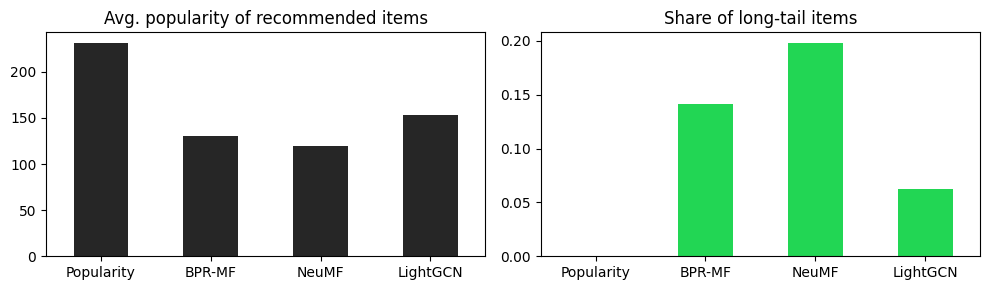

In [19]:
head_items = set(torch.argsort(pop, descending=True)[: int(n_items * 0.2)].tolist())

def popularity_stats(rec_lists):
    all_rec = [i for lst in rec_lists.values() for i in lst]
    # ===== TODO 13 =====
    # 힌트: all_rec 의 각 영화에 대해 pop[i] 평균, 그리고 head_items 에 없는 영화의 비율
    avg_pop = float(np.mean([pop[i].item() for i in all_rec]))      # TODO: 여기에 코드를 작성하세요
    tail_ratio = float(np.mean([i not in head_items for i in all_rec]))   # TODO: 여기에 코드를 작성하세요
    # ==================
    return {"avg_popularity": avg_pop, "longtail_ratio": tail_ratio}


bias = {}
for name, fn in [("Popularity", lambda users: pop.to(device).unsqueeze(0).repeat(len(users), 1)),
                 ("BPR-MF", mf.full_scores), ("NeuMF", neumf.full_scores), ("LightGCN", lgcn.full_scores)]:
    _, lists = evaluate(fn, return_lists=True)
    bias[name] = popularity_stats(lists)
bias_df = pd.DataFrame(bias).T
display(bias_df.style.format({"avg_popularity": "{:.1f}", "longtail_ratio": "{:.1%}"}))

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
bias_df["avg_popularity"].plot.bar(ax=axs[0], color="#262626", rot=0, title="Avg. popularity of recommended items")
bias_df["longtail_ratio"].plot.bar(ax=axs[1], color="#22D654", rot=0, title="Share of long-tail items")
plt.tight_layout(); plt.show()

#### 📝 서술형 문제 6
1. LightGCN의 추천은 BPR-MF보다 인기작 쪽으로 더 치우쳤나요, 덜 치우쳤나요? 두 지표를 인용하세요.
2. 결과를 근거로 "LightGCN의 정규화는 인기 편향을 해결한다"는 문장이 맞는지 판단하세요.
3. 정확도(7장)와 다양성(10장) 사이에 **트레이드오프**가 보였다면, 실제 서비스라면 어떤 기준으로 모델을 고르겠는지 한두 문장으로 적으세요.

**1.** 더 치우쳤습니다. 추천된 영화의 평균 인기도는 LightGCN 153.1로 BPR-MF 130.3보다 높고, long-tail 비율은 LightGCN 6.3%로 BPR-MF 14.1%보다 낮습니다. 참고로 인기순 추천은 231.1 / 0.0%, NeuMF는 120.0 / 19.8%였습니다.

**2.** 제 결과로는 맞지 않습니다. 대칭 정규화 D^(-1/2) A D^(-1/2)는 차수가 큰 노드에서 오는 신호를 1/sqrt(deg)로 줄여 주기는 하지만, 인기 영화는 애초에 연결된 경로 자체가 훨씬 많습니다. 정규화로 한 경로의 크기를 줄여도 경로 수가 많으면 합은 여전히 큽니다. 게다가 층을 쌓을수록 인기 노드는 거의 모든 사용자에게서 2~3 hop 안에 닿기 때문에, 전파를 하는 모델이 전파를 하지 않는 MF보다 오히려 인기 쪽으로 쏠렸다고 봅니다. 세션 39p의 '정규화만으로 인기 편향이 해결되지는 않는다'가 숫자로 확인된 셈입니다.

**3.** 트레이드오프가 보였습니다. 정확도 1위인 LightGCN이 다양성은 꼴찌에 가깝고(6.3%), 정확도 꼴찌인 NeuMF가 다양성은 가장 높았습니다(19.8%). 실제 서비스라면 저는 지표 하나로 고르지 않고, 정확도는 LightGCN 수준을 유지하되 long-tail 비율에 하한(예: 15% 이상)을 두는 식으로 제약을 걸고 그 안에서 정확도를 최대화하는 쪽을 택하겠습니다. 신작이나 비인기작이 계속 안 팔리면 새 상호작용 데이터가 안 쌓여서 다음 학습 때 더 밀리는 악순환이 생기기 때문입니다.

#### 🤔 회고

Part A에서 겪은 어려움과 해결 과정을 3-5문장으로 적습니다. 끝까지 헷갈린 개념 1-3개도 함께: 가장 오래 붙잡은 건 Negative Sampling이었습니다. 처음에는 torch.randint로 한 번만 뽑고 끝냈는데 셀 23의 확인 코드(neg 중에 사용자가 본 영화가 섞여 있습니다)에서 걸렸고, 걸린 자리만 다시 뽑는 while 루프로 고쳤습니다. NDCG의 IDCG도 헷갈렸습니다. 정답 개수가 K보다 많을 때를 생각 못 해서 min(len(truth), len(ranked))로 잡아야 세션 예시 0.70이 나왔습니다. 끝까지 헷갈린 개념은 두 가지입니다. 하나는 정규화 행렬에서 왜 D^(-1)이 아니라 D^(-1/2)를 양쪽에 곱하는지(대칭성을 지키기 위한 것까지는 이해했지만 비대칭 정규화와의 성능 차이는 직접 실험해 보지 않았습니다), 다른 하나는 BPR 손실이 줄어드는데도 Recall이 떨어지는 구간(epoch 20 이후)을 어디까지 과적합으로 봐야 하는지입니다.

Part B(심화 선택)를 진행했다면, 세션 내용과 **다르게 나온 결과**와 그로부터 배운 점을 이어서 적어도 좋습니다: Part B에서 예상과 가장 달랐던 건 층 수였습니다. 3층이 기본값이길래 3층이 제일 좋을 줄 알았는데 2층(0.3539)이 가장 높고 3층 0.3415, 4층 0.3320으로 내려갔습니다. 층별 cosine 유사도가 0.02에서 0.75까지 단조로 올라가는 걸 보고서야 over-smoothing이 이론이 아니라 이 작은 데이터에서도 바로 나타나는 현상이라는 걸 알았습니다. 인기 편향 실험도 예상과 반대였습니다. 정규화가 들어간 LightGCN이 MF보다 덜 치우칠 줄 알았는데 평균 인기도 153.1 대 130.3, long-tail 6.3% 대 14.1%로 오히려 더 쏠렸습니다. 정확도가 가장 높은 모델이 다양성은 가장 나쁠 수 있다는 걸 숫자로 본 게 이번 과제에서 제일 남습니다.

#### ⚙️ 생성형 AI 활용 (비판적 사용)

AI는 **검산기, 설명 도우미**로 활용하고 최종 판단은 본인이 합니다.

- **어디에 썼나** (PyTorch 문법 디버깅, 개념 설명, 에러 해석 등 구체적으로): 세 군데에 썼습니다. (1) torch.sparse.mm과 coalesce를 쓸 때 인덱스 shape이 (2, nnz)여야 하는지 확인했습니다. (2) jaccard.fill_diagonal_(0.0)처럼 in-place 메서드를 쓸 때 autograd와 충돌이 없는지 물었습니다. (3) NDCG의 IDCG 정의가 '정답을 전부 맨 위에 놓았을 때의 DCG'가 맞는지 개념 확인에 썼습니다. 코드는 먼저 제가 쓰고, 확인 셀이 깨졌을 때만 물어보는 식으로 썼습니다.

- **AI가 이 실험에는 틀린 답을 준 사례**
  본인이 겪은 사례와, 그것을 **어떻게 알아채고 고쳤는지**(본인 출력값과 대조 / 공식 문서 확인 / 직접 실험) 적으세요: 두 번 있었습니다. 첫째, BPR 손실을 물었을 때 -log(sigmoid(pos - neg))를 그대로 쓰라는 답을 받았습니다. 그대로 넣었더니 셀 23의 확인값(bpr_loss(2.0, 0.0) ≈ 0.1269)은 통과했지만 학습 중간에 nan이 뜨는 경우가 있었고, 힌트에 적힌 F.logsigmoid로 바꾸니 사라졌습니다. 수식은 같아도 수치 안정성이 다르다는 걸 그때 알았습니다. 둘째, '층을 깊게 쌓을수록 더 많은 정보를 보니까 LightGCN은 층이 깊을수록 좋아진다'는 설명을 받았습니다. 제 8장 결과는 2층 0.3539 이후 3층 0.3415, 4층 0.3320으로 내려갔고, 층별 cosine 유사도가 0.02에서 0.75로 올라가는 그래프가 그 이유를 보여줬습니다. AI 설명 대신 제 출력값을 근거로 '2층이 최적, 그 뒤는 over-smoothing'이라고 결론을 적었습니다.

- **실제 대화 내역** 붙여넣기:

```
나: LightGCN에서 층을 깊게 쌓을수록 더 많은 이웃 정보를 보니까 성능도 계속 좋아지는 게 맞아?
AI: 네, 층이 깊어질수록 더 넓은 범위의 고차 이웃 정보를 집계하므로 일반적으로 성능이 향상됩니다.
    보통 3~4층 정도가 권장됩니다.

나: 내가 0~4층을 같은 조건으로 돌려봤는데 Recall@20이 0.3037 / 0.3433 / 0.3539 / 0.3415 / 0.3320이야.
    2층이 제일 좋고 그 뒤로는 떨어지는데?
AI: 그렇다면 학습이 부족했을 가능성이 있습니다. epoch을 늘리거나 임베딩 차원을 키워 보세요.

나: 4층 모델의 층별 평균 cosine 유사도를 재봤더니 0.02 → 0.13 → 0.33 → 0.64 → 0.75로 계속 올라가.
    이건 학습 부족이 아니라 벡터가 서로 비슷해지는 거 아니야?
AI: 맞습니다. 층이 깊어질수록 노드 표현이 서로 수렴하는 over-smoothing 현상입니다.
    데이터셋이 작고 그래프 지름이 짧으면 더 이른 층에서 나타날 수 있습니다.

나: 그럼 내 결론은 '이 데이터에서는 2층이 최적이고 그 이후는 over-smoothing'으로 가는 게 맞겠다.
    (epoch을 늘리라는 첫 답변은 내 cosine 측정값과 맞지 않아서 따르지 않음)

---

나: BPR 손실은 -log(sigmoid(pos - neg)) 평균으로 짜면 되지?
AI: 네, torch.log(torch.sigmoid(pos_score - neg_score))의 평균에 음수를 취하면 됩니다.

나: 그렇게 했더니 확인값(0.1269)은 맞는데 학습 중에 가끔 nan이 떠.
AI: pos - neg 차이가 크게 음수가 되면 sigmoid가 0에 가까워져 log에서 발산할 수 있습니다.
    F.logsigmoid를 쓰면 내부적으로 안정적으로 계산됩니다.

나: F.logsigmoid로 바꾸니 nan이 사라졌음. 수식이 같아도 구현에 따라 다르다는 걸 확인.
```

- 마지막 한 문장: **AI가 대신할 수 없었던 나만의 판단**은 무엇이었나요? 숫자가 세션 슬라이드와 어긋났을 때(층 수는 3층이 아니라 2층이 최적이었고, 정규화를 쓴 LightGCN이 오히려 더 인기 편향이 심했습니다) 결과를 슬라이드에 맞춰 고치지 않고 제 출력값을 그대로 적고 원인을 추론하기로 한 판단이었습니다.

#### 📚 참고 자료

**Part A**
- BPR: Rendle et al., [BPR: Bayesian Personalized Ranking from Implicit Feedback](https://arxiv.org/abs/1205.2618) (UAI 2009)
- NCF: He et al., [Neural Collaborative Filtering](https://arxiv.org/abs/1708.05031) (WWW 2017)
- LightGCN: He et al., [LightGCN: Simplifying and Powering Graph Convolution Network for Recommendation](https://arxiv.org/abs/2002.02126) (SIGIR 2020)
- MovieLens: Harper & Konstan, [The MovieLens Datasets: History and Context](https://dl.acm.org/doi/10.1145/2827872) (ACM TiiS 2015)

**Part B**
- NGCF: Wang et al., [Neural Graph Collaborative Filtering](https://arxiv.org/abs/1905.08108) (SIGIR 2019)
- MF vs NCF 재검증: Rendle et al., [Neural Collaborative Filtering vs. Matrix Factorization Revisited](https://arxiv.org/abs/2005.09683) (RecSys 2020)
- 강의 자료: [Stanford CS224W](https://web.stanford.edu/class/cs224w/)